# Assignment No. 5

## Implementation of K-Means Clustering on Sales Dataset

### Objective

- To understand the basic concepts of the K-Means clustering algorithm.
- To understand the implementation logic of K-Means clustering.
- To determine the suitable number of clusters using the Elbow Method.

The dataset used is `sales_data_sample.csv`.

## Import Required Libraries

We import the libraries required for data handling, preprocessing, clustering, and visualization.

- `pandas` is used to read and manipulate the dataset.
- `matplotlib` is used to visualize the data and results.
- `KMeans` from Scikit-learn is used to implement the K-Means clustering algorithm.
- `StandardScaler` is used to scale the numerical features.

Feature scaling is useful because K-Means uses distance to determine which data points belong to the same cluster.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

## Load the Dataset

The `sales_data_sample.csv` file contains information about sales orders.

We use `pd.read_csv()` to load the CSV file into a Pandas DataFrame.

The `head()` function displays the first five rows so that we can understand the structure of the dataset.

The sales dataset contains some special characters, so ISO-8859-1 encoding helps Pandas read the CSV correctly

In [2]:

df = pd.read_csv(r"C:\Users\rushi\Downloads\archive (2)\sales_data_sample.csv", encoding='ISO-8859-1')
df.head()

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium


## Explore the Dataset

Before applying clustering, we check the structure of the dataset.

`df.info()` displays the number of rows, columns, column names, data types, and non-null values.

This helps us identify which columns can be used for clustering.

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2823 entries, 0 to 2822
Data columns (total 25 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ORDERNUMBER       2823 non-null   int64  
 1   QUANTITYORDERED   2823 non-null   int64  
 2   PRICEEACH         2823 non-null   float64
 3   ORDERLINENUMBER   2823 non-null   int64  
 4   SALES             2823 non-null   float64
 5   ORDERDATE         2823 non-null   object 
 6   STATUS            2823 non-null   object 
 7   QTR_ID            2823 non-null   int64  
 8   MONTH_ID          2823 non-null   int64  
 9   YEAR_ID           2823 non-null   int64  
 10  PRODUCTLINE       2823 non-null   object 
 11  MSRP              2823 non-null   int64  
 12  PRODUCTCODE       2823 non-null   object 
 13  CUSTOMERNAME      2823 non-null   object 
 14  PHONE             2823 non-null   object 
 15  ADDRESSLINE1      2823 non-null   object 
 16  ADDRESSLINE2      302 non-null    object 


## Display Statistical Summary

The `describe()` function provides basic statistical information about numerical columns.

It displays values such as:

- Count
- Mean
- Standard deviation
- Minimum
- Maximum

This helps us understand the range and distribution of the sales data.

In [4]:
df.describe()

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,QTR_ID,MONTH_ID,YEAR_ID,MSRP
count,2823.000000,2823.000000,2823.000000,2823.000000,2823.000000,2823.000000,2823.000000,2823.00000,2823.000000
mean,10258.725115,35.092809,83.658544,6.466171,3553.889072,2.717676,7.092455,2003.81509,100.715551
std,92.085478,9.741443,20.174277,4.225841,1841.865106,1.203878,3.656633,0.69967,40.187912
min,10100.000000,6.000000,26.880000,1.000000,482.130000,1.000000,1.000000,2003.00000,33.000000
25%,10180.000000,27.000000,68.860000,3.000000,2203.430000,2.000000,4.000000,2003.00000,68.000000
50%,10262.000000,35.000000,95.700000,6.000000,3184.800000,3.000000,8.000000,2004.00000,99.000000
75%,10333.500000,43.000000,100.000000,9.000000,4508.000000,4.000000,11.000000,2004.00000,124.000000
max,10425.000000,97.000000,100.000000,18.000000,14082.800000,4.000000,12.000000,2005.00000,214.000000


## Select Features for Clustering

K-Means requires numerical input features.

For this practical, we use:

- `SALES` — total sales amount.
- `QUANTITYORDERED` — quantity of products ordered.

These two features are directly related to sales activity and are suitable for demonstrating customer/order clustering.

We do not use the target variable because K-Means is an unsupervised learning algorithm and does not require predefined labels.

In [5]:
data = df[["SALES", "QUANTITYORDERED"]]

data.head()

,SALES,QUANTITYORDERED
0,2871.00,30
1,2765.90,34
2,3884.34,41
3,3746.70,45
4,5205.27,49


## Check for Missing Values

Missing values can cause problems during clustering.

We use `isnull().sum()` to count the missing values in each selected feature.

If there are no missing values, we can directly continue with scaling.

In [6]:
data.isnull().sum()

SALES              0
QUANTITYORDERED    0
dtype: int64

## Standardize the Features

K-Means clustering is based on distance between data points.

The `SALES` and `QUANTITYORDERED` features have different numerical ranges. If we use them directly, the feature with the larger numerical range can have a greater influence on the distance calculation.

`StandardScaler` converts the features to a comparable scale.

The scaled data is stored in `scaled_data`.

In [7]:
scaler = StandardScaler()

scaled_data = scaler.fit_transform(data)

scaled_data[:5]

array([[-0.37082523, -0.52289086],
       [-0.42789707, -0.11220131],
       [ 0.17944282,  0.60650538],
       [ 0.10470098,  1.01719493],
       [ 0.89673966,  1.42788447]])

## Determine the Number of Clusters Using the Elbow Method

The Elbow Method is used to find a suitable value of K.

We calculate the WCSS (Within-Cluster Sum of Squares) for different values of K.

WCSS measures how close the data points are to the centroid of their assigned cluster.

As the number of clusters increases, WCSS decreases.

We calculate WCSS for K values from 1 to 10 and store the values in a list.

In [8]:
wcss = []

for k in range(1, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    model.fit(scaled_data)
    wcss.append(model.inertia_)

## Plot the Elbow Curve

The WCSS values are plotted against the number of clusters.

The graph usually decreases rapidly at first and then starts decreasing more slowly.

The point where the rate of decrease changes significantly is called the elbow point.

This point gives us a suitable value of K for the K-Means algorithm.

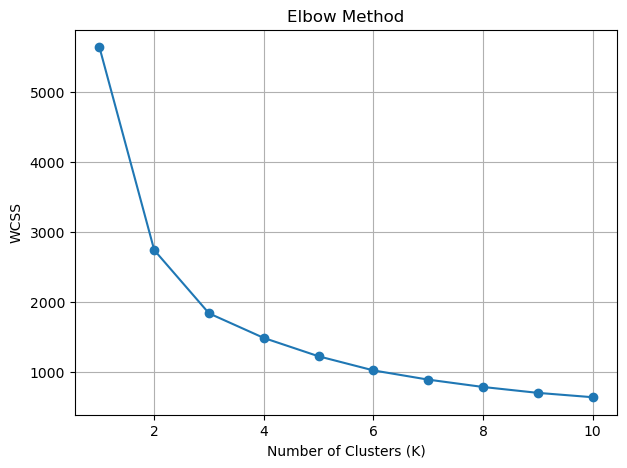

In [9]:
plt.figure(figsize=(7, 5))

plt.plot(range(1, 11), wcss, marker="o")

plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.title("Elbow Method")

plt.grid()
plt.show()

## Select the Optimal Number of Clusters

From the Elbow Method graph, the elbow point is used to select the appropriate number of clusters.

For this practical, we use:

\[
K = 3
\]

This means the dataset will be divided into three clusters.

In [10]:
k = 3

## Apply K-Means Clustering

We now create the K-Means model using the selected value of K.

K-Means works through the following basic steps:

1. Select K initial centroids.
2. Assign each data point to the nearest centroid.
3. Calculate new centroids.
4. Reassign the data points based on the new centroids.
5. Repeat the process until the clusters become stable.

The `fit_predict()` function performs the clustering and returns the cluster number assigned to every data point.

In [11]:
model = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
)

clusters = model.fit_predict(scaled_data)

clusters[:10]

array([1, 2, 2, 2, 0, 2, 1, 0, 1, 2], dtype=int32)

## Add Cluster Labels to the Dataset

The K-Means algorithm assigns a cluster number to every data point.

We add these cluster numbers to our original selected-data DataFrame using a new column called `Cluster`.

The cluster numbers start from 0.

In [12]:
data["Cluster"] = clusters

data.head()

C:\Users\rushi\AppData\Local\Temp\ipykernel_14456\2592363688.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data["Cluster"] = clusters


,SALES,QUANTITYORDERED,Cluster
0,2871.00,30,1
1,2765.90,34,2
2,3884.34,41,2
3,3746.70,45,2
4,5205.27,49,0


## Visualize the K-Means Clusters

The clusters are visualized using a scatter plot.

- X-axis represents `QUANTITYORDERED`.
- Y-axis represents `SALES`.
- Different colors represent different clusters.

This allows us to visually observe how K-Means has grouped the sales records.

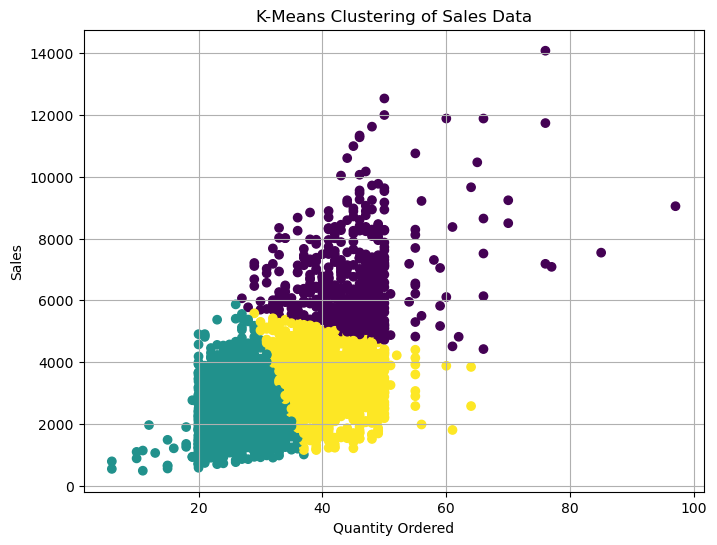

In [13]:
plt.figure(figsize=(8, 6))

plt.scatter(
    data["QUANTITYORDERED"],
    data["SALES"],
    c=data["Cluster"]
)

plt.xlabel("Quantity Ordered")
plt.ylabel("Sales")
plt.title("K-Means Clustering of Sales Data")

plt.grid()
plt.show()

## Display Cluster Centroids

A centroid represents the center of a cluster.

The K-Means algorithm calculates a centroid for each cluster.

Because the model was trained on scaled data, the centroid values are currently in the scaled form.

We can convert the centroid values back to the original scale to make them easier to understand.

In [14]:
centers = scaler.inverse_transform(model.cluster_centers_)

centers_df = pd.DataFrame(
    centers,
    columns=["SALES", "QUANTITYORDERED"]
)

centers_df

,SALES,QUANTITYORDERED
0,6583.478112,44.840077
1,2427.462119,26.264286
2,3407.281073,40.902299


## Cluster Summary

The number of data points belonging to each cluster is calculated to understand the final grouping.

This gives a simple summary of how the sales records were divided by the K-Means algorithm.

In [15]:
print("Number of data points in each cluster:")

print(data["Cluster"].value_counts().sort_index())

Number of data points in each cluster:
Cluster
0     520
1    1259
2    1044
Name: count, dtype: int64


# Viva Questions and Answers

## 1. What is K-Means clustering?

K-Means is an **unsupervised machine learning algorithm** used to divide data into a specified number of clusters based on similarity or distance.

---

## 2. Why is K-Means called an unsupervised algorithm?

K-Means is unsupervised because the dataset does not contain predefined target labels. The algorithm itself discovers groups or clusters from the input data.

---

## 3. Why is it called K-Means?

**K** represents the number of clusters, while **Means** refers to the mean or average position used to calculate the center of each cluster.

---

## 4. What is a cluster?

A cluster is a group of data points that are similar to each other and different from points belonging to other clusters.

---

## 5. What is a centroid?

A centroid is the center point of a cluster. It represents the average position of all the data points belonging to that cluster.

---

## 6. How does the K-Means algorithm work?

K-Means generally works in these steps:

1. Select the number of clusters, K.
2. Initialize K centroids.
3. Assign each data point to the nearest centroid.
4. Calculate new centroids using the mean of the assigned points.
5. Repeat the assignment and centroid calculation steps.
6. Stop when the centroids become stable or the algorithm reaches its stopping condition.

---

## 7. What is the purpose of the Elbow Method?

The Elbow Method is used to determine a suitable number of clusters for K-Means.

It calculates WCSS for different values of K and plots the values. The point where the decrease in WCSS becomes less significant is called the **elbow point**.

---

## 8. What is WCSS?

WCSS stands for **Within-Cluster Sum of Squares**.

It measures how close the data points are to the centroid of their assigned cluster.

A lower WCSS means that the data points are closer to their cluster centroids.

---

## 9. Why does WCSS decrease when K increases?

When the number of clusters increases, each cluster generally contains fewer data points. Therefore, the points become closer to their respective centroids, causing WCSS to decrease.

---

## 10. Why can't we simply choose a very large value of K?

A very large K can create too many small clusters and may not provide meaningful grouping.

The Elbow Method helps us select a reasonable value of K that balances simplicity and clustering quality.

---

## 11. Why did we use SALES and QUANTITYORDERED?

We selected `SALES` and `QUANTITYORDERED` because they are numerical features directly related to sales activity and are suitable for demonstrating clustering.

---

## 12. Why did we scale the data?

K-Means uses distance to determine the nearest cluster.

The features may have different numerical ranges. Scaling puts them on a comparable scale so that a feature with larger numerical values does not dominate the distance calculation.

---

## 13. What does StandardScaler do?

`StandardScaler` standardizes numerical features so that they have approximately:

- Mean = 0
- Standard deviation = 1

This makes the features comparable for distance-based algorithms such as K-Means.

---

## 14. Why do we use `fit_transform()` for scaling?

`fit_transform()` first calculates the required scaling parameters from the data and then transforms the data using those parameters.

In this practical:

```python
scaled_data = scaler.fit_transform(data)